# From probabilistic to deflated Sharpe ratios

A sample Sharpe ratio compares the average return with the observed return variation:

$$
\widehat{SR}=\frac{\overline r}{s_r},
\qquad
\overline r=\frac{1}{T}\sum_{t=1}^{T}r_t,
\qquad
s_r^2=\frac{1}{T-1}\sum_{t=1}^{T}(r_t-\overline r)^2.
$$

Here, $r_t$ is the return at observation $t$, $T$ is the number of returns, $\overline r$ is their sample mean, $s_r$ is their sample standard deviation, and $\widehat{SR}$ is the per-period sample Sharpe ratio when the comparison return is zero.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("20_sharpe_multiple_testing");
using CSV, TOML, Printf
prefix = "probabilistic"
source_path = dataset_path("fred_sp500")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
returns = vcat(NaN,diff(log.(prices)))

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    result[1:span-1] .= NaN
    return result
end

columns,catalog_records = Vector{Float64}[],NamedTuple[]
for fast in [3,5,10,20], slow in [30,60,120,240]
    fast_average,slow_average = exponential_average(prices,fast),exponential_average(prices,slow)
    signal = sign.(fast_average.-slow_average)
    for index in 2:length(signal)
        signal[index]==0 && (signal[index]=signal[index-1])
    end
    position = vcat(NaN,signal[1:end-1])
    for (orientation,multiplier) in [("Trend",1.),("Reversal",-1.)]
        name = orientation*" "*string(fast)*"/"*string(slow)
        push!(columns,multiplier.*position.*returns)
        push!(catalog_records,(trial=length(catalog_records)+1,rule=orientation,fast=fast,slow=slow,name=name))
    end
end
complete = findall(vec(all(isfinite,reduce(hcat,columns);dims=2)))
performances = reduce(hcat,columns)[complete,:]
dates = price_dates[complete]
strategy_catalog = DataFrame(catalog_records)
rename!(strategy_catalog,["Trial","Rule","Fast span","Slow span","Name"])
names_trials = strategy_catalog.Name
@assert size(performances)==(2090,32)
performance_frame = DataFrame(performances,names_trials)
insertcols!(performance_frame,1,:date=>dates)
save_data(performance_frame,paths,prefix*"_performances")
save_data(DataFrame(date=price_dates,price=prices),paths,prefix*"_prices")
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter20-"*replace(name,"_"=>"-"))

using Distributions: Normal,quantile
using RiskLabAI.Backtest: probabilistic_sharpe_ratio,benchmark_sharpe_ratio,lplz_sharpe_inference,newey_west_automatic_lag,newey_west_long_run_variance,sharpe_ratio_influence_function,benjamini_hochberg_yekutieli_adjusted_p_values,haircut_sharpe_ratios,holm_adjusted_p_values,sharpe_ratio_p_values,expected_max_sharpe_ratio,estimated_sharpe_ratio_z_statistics,strategy_type1_error_probability,strategy_type2_error_probability,theta_for_type2_error,sharpe_difference_test

function period_sharpe(values)
    deviation = std(values)
    return deviation>0 ? mean(values)/deviation : 0.
end

function return_moments(values)
    n = length(values)
    centered = values.-mean(values)
    second,third,fourth = mean(centered.^2),mean(centered.^3),mean(centered.^4)
    skewness = sqrt(n*(n-1))/(n-2)*third/second^1.5
    kurtosis = (n-1)/((n-2)*(n-3))*((n+1)*(fourth/second^2-3)+6)+3
    return skewness,kurtosis
end

psr(sharpe,benchmark,n,skewness=0.,kurtosis=3.;return_test_statistic=false) = probabilistic_sharpe_ratio(sharpe,benchmark,n;skewness_of_returns=skewness,kurtosis_of_returns=kurtosis,return_test_statistic)
opposite_name(name) = startswith(name,"Trend") ? replace(name,"Trend"=>"Reversal") : replace(name,"Reversal"=>"Trend")
trial_sharpes = period_sharpe.(eachcol(performances))
annual_sharpes = trial_sharpes.*sqrt(252.)
trial_mean,trial_spread = mean(trial_sharpes),std(trial_sharpes;corrected=false)
observation_count,trial_count = size(performances)

function read_primitive(name)
    root = joinpath("..","data","chapter20_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    metadata = TOML.parsefile(manifest_path)["files"][name*".bin"]
    path = joinpath(root,name*".bin")
    values = reinterpret(Float64,ltoh.(reinterpret(UInt64,read(path))))
    @assert length(values)==metadata["values"]
    return reshape(values,Tuple(metadata["shape"]))
end

function ar1_values(innovations,persistence;scale=.01)
    values = zeros(size(innovations))
    for index in 2:size(values,1)
        values[index,:] = persistence.*values[index-1,:].+scale.*innovations[index,:]
    end
    return values
end


ar1_values (generic function with 1 method)

## Public Trial Family

Row,Field,Value
,String,String
1,Series,S&P 500
2,Provider,Federal Reserve Bank of St. Louis
3,Source,https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31
4,Retrieved,2026-09-28
5,First price,2016-09-26
6,Last price,2025-12-31
7,Price observations,"2,330"
8,Trial observations,"2,090"
9,Trials,32


Row,Trial,Name,Annual Sharpe,Skewness,Kurtosis,PSR against zero,Expected maximum benchmark,Deflated probability
,Int64,String,Float64,Float64,Float64,Float64,Float64,Float64
1,1,Trend 3/30,0.368432,0.187386,18.2114,0.855851,0.589005,0.262481
2,2,Reversal 3/30,-0.368432,-0.187386,18.2114,0.144149,0.589005,0.00289503
3,3,Trend 3/60,0.252547,0.125187,18.2122,0.766527,0.589005,0.166232
4,4,Reversal 3/60,-0.252547,-0.125187,18.2122,0.233473,0.589005,0.00767375
5,5,Trend 3/120,0.290021,0.0456063,18.2193,0.798077,0.589005,0.194738
6,6,Reversal 3/120,-0.290021,-0.0456063,18.2193,0.201923,0.589005,0.0057013
7,7,Trend 3/240,0.19922,-0.0502824,18.2198,0.716751,0.589005,0.131032
8,8,Reversal 3/240,-0.19922,0.0502824,18.2198,0.283249,0.589005,0.0116659
9,9,Trend 5/30,0.448622,0.276929,18.2054,0.902255,0.589005,0.34271


Row,Trial,Name,Annual Sharpe,Skewness,Kurtosis,PSR against zero,Expected maximum benchmark,Deflated probability
,Int64,String,Float64,Float64,Float64,Float64,Float64,Float64
1,9,Trend 5/30,0.448622,0.276929,18.2054,0.902255,0.589005,0.34271
2,27,Trend 20/60,0.413375,0.111026,18.2215,0.883009,0.589005,0.306547
3,13,Trend 5/120,0.370794,0.0484253,18.2245,0.856999,0.589005,0.265039
4,1,Trend 3/30,0.368432,0.187386,18.2114,0.855851,0.589005,0.262481
5,21,Trend 10/120,0.356375,0.098711,18.2189,0.847576,0.589005,0.251493
6,17,Trend 10/30,0.342441,0.261665,18.204,0.838362,0.589005,0.23848
7,5,Trend 3/120,0.290021,0.0456063,18.2193,0.798077,0.589005,0.194738
8,3,Trend 3/60,0.252547,0.125187,18.2122,0.766527,0.589005,0.166232
9,15,Trend 5/240,0.250915,0.0209977,18.2187,0.764902,0.589005,0.165262


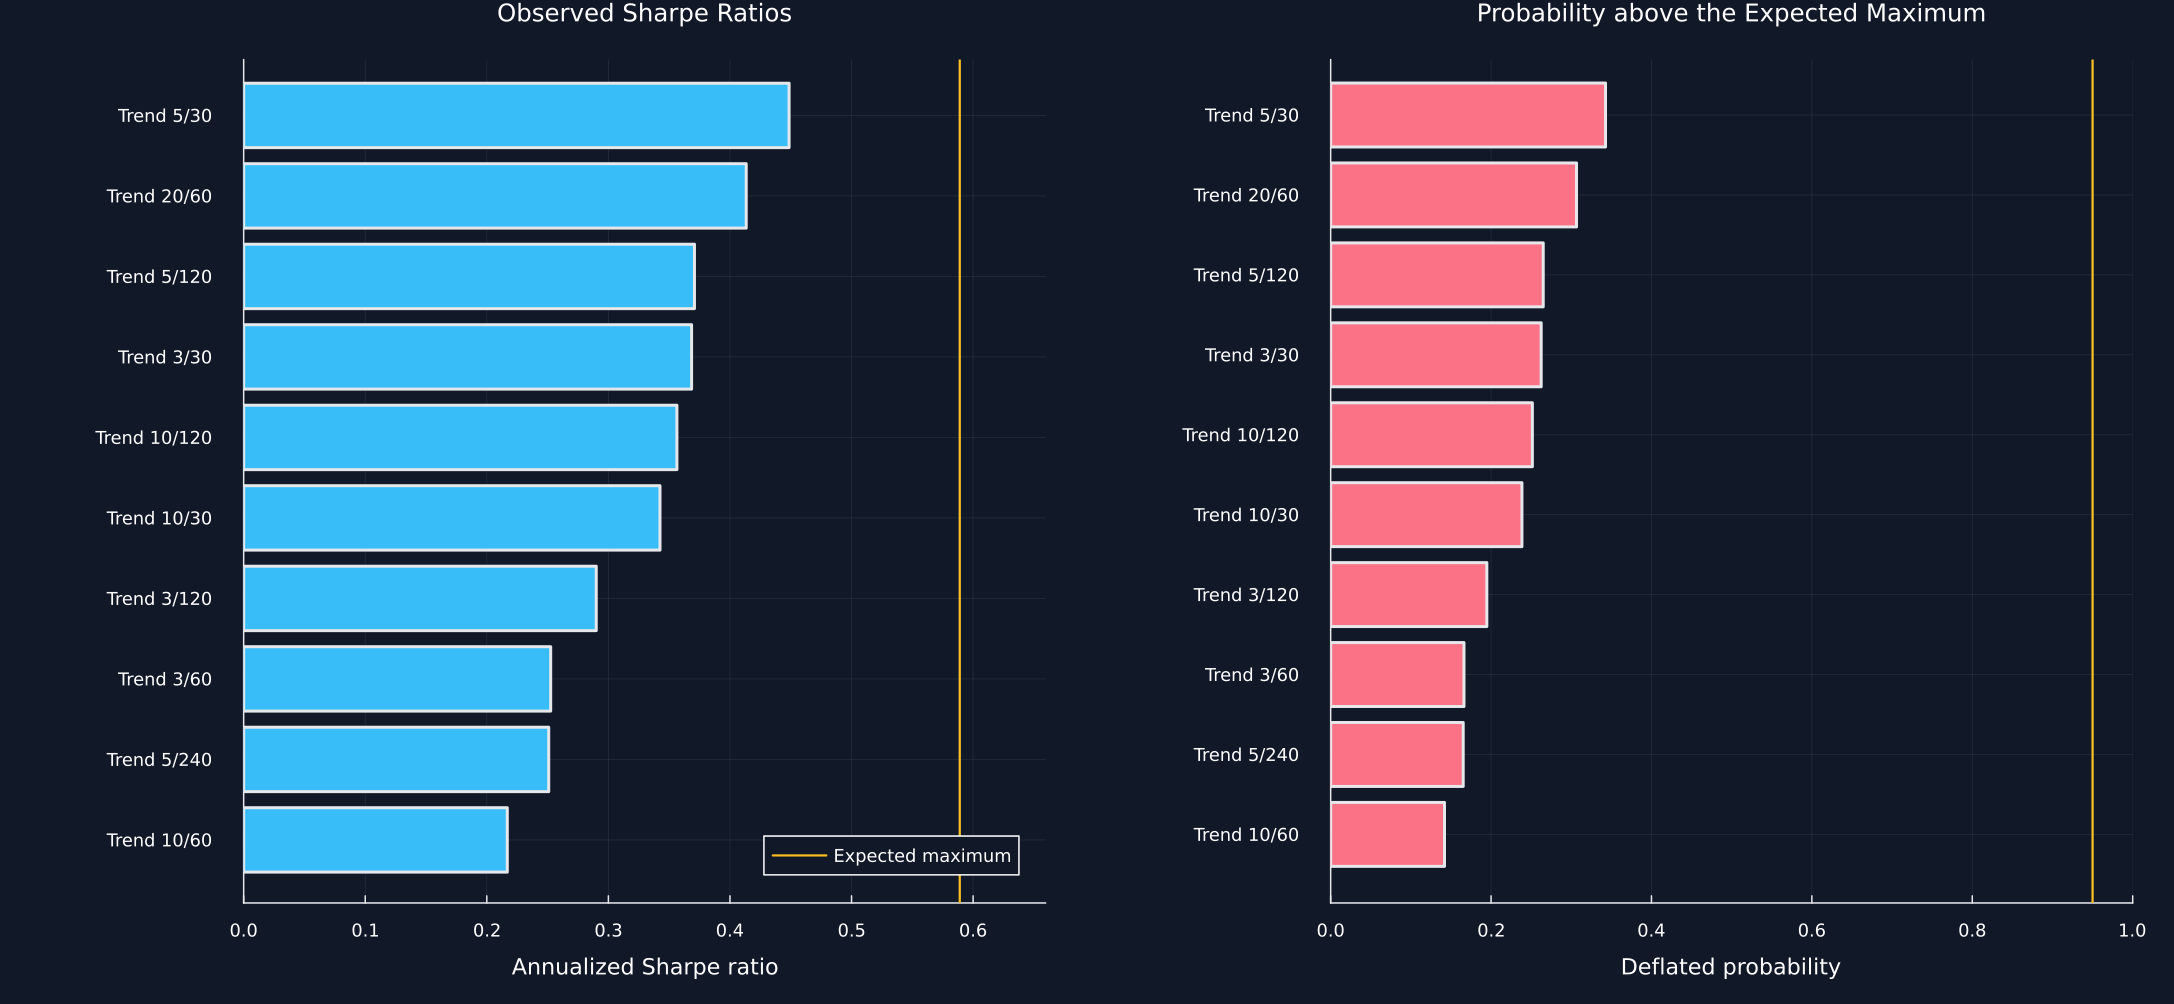

In [2]:
data_provenance = DataFrame("Field"=>["Series","Provider","Source","Retrieved","First price","Last price","Price observations","Trial observations","Trials"],"Value"=>["S&P 500","Federal Reserve Bank of St. Louis","https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31","2026-09-28",string(first(price_dates)),string(last(price_dates)),"2,330","2,090","32"])
expected_maximum = expected_max_sharpe_ratio(trial_count,trial_mean,trial_spread)
inference_rows = NamedTuple[]
for (trial,name) in enumerate(names_trials)
    values = performances[:,trial]
    sharpe = period_sharpe(values)
    skewness,kurtosis = return_moments(values)
    push!(inference_rows,(trial=trial,name=name,sharpe=sharpe*sqrt(252.),skewness=skewness,kurtosis=kurtosis,psr=psr(sharpe,0.,length(values),skewness,kurtosis),benchmark=expected_maximum*sqrt(252.),deflated=psr(sharpe,expected_maximum,length(values),skewness,kurtosis)))
end
public_sharpe_inference = DataFrame(inference_rows)
rename!(public_sharpe_inference,["Trial","Name","Annual Sharpe","Skewness","Kurtosis","PSR against zero","Expected maximum benchmark","Deflated probability"])
leading_public_inference = first(sort(public_sharpe_inference,["Annual Sharpe","Trial"];rev=[true,false]),10)
table(data_provenance,"data_provenance","Public observations used for Sharpe inference.")
table(public_sharpe_inference,"public_sharpe_inference","Sharpe inference for every public trial.")
table(leading_public_inference,"leading_public_inference","The ten largest full-sample Sharpe ratios and their probability adjustments.")
leading = sort(leading_public_inference,"Annual Sharpe")
p1 = bar(1:10,leading[!,"Annual Sharpe"];orientation=:h,color=palette.cyan,label="",yticks=(1:10,leading.Name),xlims=(0,1.12*max(expected_maximum*sqrt(252.),maximum(leading[!,"Annual Sharpe"]))),title="Observed Sharpe Ratios",xlabel="Annualized Sharpe ratio",legend=:bottomright)
vline!(p1,[expected_maximum*sqrt(252.)];color=palette.amber,label="Expected maximum",linewidth=1.5)
p2 = bar(1:10,leading[!,"Deflated probability"];orientation=:h,color=ifelse.(leading[!,"Deflated probability"].>=.95,palette.green,palette.rose),label="",yticks=(1:10,leading.Name),xlims=(0,1),title="Probability above the Expected Maximum",xlabel="Deflated probability")
vline!(p2,[.95];color=palette.amber,label="",linewidth=1.5)
save_figure(plot(p1,p2;layout=(1,2),size=(1450,670),left_margin=15Plots.mm,bottom_margin=8Plots.mm),paths,"public_deflated_sharpe")


A multiple-trial benchmark approximates the expected largest Sharpe ratio in a family of independent normal estimates:

$$
SR^*_{N}
=\mu_{SR}+\sigma_{SR}\left[(1-\gamma)\Phi^{-1}\!\left(1-\frac{1}{N}\right)+\gamma\Phi^{-1}\!\left(1-\frac{1}{Ne}\right)\right].
$$

Here, $SR^*_{N}$ is the expected maximum among $N$ trials, $\mu_{SR}$ and $\sigma_{SR}$ are the mean and standard deviation of the trial Sharpe estimates, $\gamma$ is the Euler-Mascheroni constant, $\Phi^{-1}$ is the standard-normal quantile function, and $e$ is Euler's number.

## Expected Maximum under Repeated Trials

Row,Trials,Benchmark from public spread,Benchmark when mean is zero
,Int64,Float64,Float64
1,1,0.0,0.0
2,5,0.334518,0.334518
3,10,0.441669,0.441669
4,20,0.533141,0.533141
5,32,0.589005,0.589005
6,50,0.638494,0.638494
7,100,0.709824,0.709824


Row,Trials,Simulations,Analytical expected maximum,Simulated mean maximum,Simulated standard error
,Int64,Int64,Float64,Float64,Float64
1,1,5000,0.0,-0.00271271,0.00694152
2,5,5000,0.596297,0.582983,0.00478225
3,20,5000,0.950354,0.93436,0.00375351
4,100,5000,1.2653,1.25376,0.00301481


Row,Quantity,Value
,String,Float64
1,Strategies,100.0
2,Simulations,1000.0
3,Sharpe mean,0.0
4,Sharpe spread,0.5
5,Analytical expected maximum,1.2653
6,Simulated mean maximum,1.25481
7,Simulated standard error,0.00670661


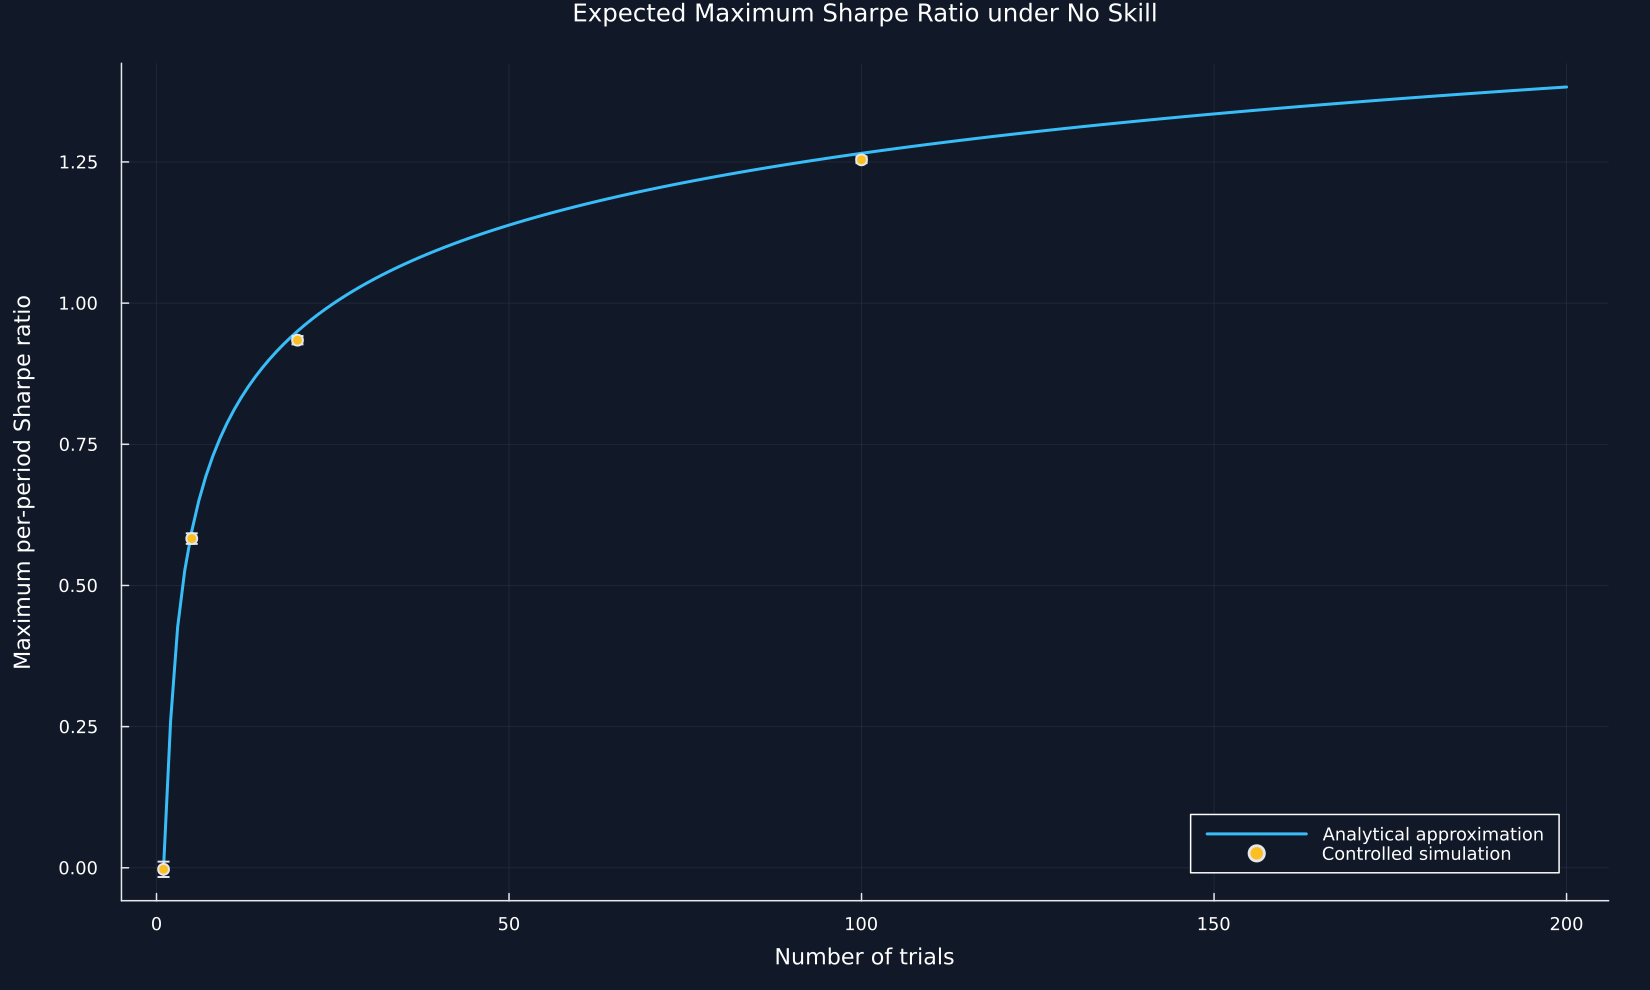

In [3]:
trial_counts = [1,5,10,20,32,50,100]
expected_maximum_sensitivity = DataFrame("Trials"=>trial_counts,"Benchmark from public spread"=>[expected_max_sharpe_ratio(count,trial_mean,trial_spread)*sqrt(252.) for count in trial_counts],"Benchmark when mean is zero"=>[expected_max_sharpe_ratio(count,0.,trial_spread)*sqrt(252.) for count in trial_counts])
simulation_rows = NamedTuple[]
for count in [1,5,20,100]
    simulated = read_primitive("maximum_"*string(count)).*0.5
    maxima = vec(maximum(simulated;dims=2))
    push!(simulation_rows,(trials=count,simulations=length(maxima),analytical=expected_max_sharpe_ratio(count,0.,.5),simulated=mean(maxima),error=std(maxima)/sqrt(length(maxima))))
    save_data(DataFrame(maximum=maxima),paths,"maximum_"*string(count))
end
expected_maximum_simulation = DataFrame(simulation_rows)
rename!(expected_maximum_simulation,["Trials","Simulations","Analytical expected maximum","Simulated mean maximum","Simulated standard error"])
preliminary_maxima = vec(maximum(read_primitive("preliminary_maximum").*0.5;dims=2))
preliminary_expected_max_reproduction = DataFrame("Quantity"=>["Strategies","Simulations","Sharpe mean","Sharpe spread","Analytical expected maximum","Simulated mean maximum","Simulated standard error"],"Value"=>[100,1000,0.,.5,expected_max_sharpe_ratio(100,0.,.5),mean(preliminary_maxima),std(preliminary_maxima)/sqrt(1000)])
table(expected_maximum_sensitivity,"expected_maximum_sensitivity","Expected maximum Sharpe ratios as the number of trials changes.")
table(expected_maximum_simulation,"expected_maximum_simulation","Analytical and simulated maximum Sharpe ratios under a known null.")
table(preliminary_expected_max_reproduction,"preliminary_expected_max_reproduction","Controlled reproduction of the preliminary one-hundred-strategy experiment.")
save_data(DataFrame(maximum=preliminary_maxima),paths,"preliminary_maximum")
count_grid = collect(1:200)
analytic_curve = [expected_max_sharpe_ratio(count,0.,.5) for count in count_grid]
save_data(DataFrame(trials=count_grid,expected=analytic_curve),paths,"expected_maximum_curve")
figure = plot(count_grid,analytic_curve;color=palette.cyan,label="Analytical approximation",xlabel="Number of trials",ylabel="Maximum per-period Sharpe ratio",title="Expected Maximum Sharpe Ratio under No Skill",legend=:bottomright,size=(1100,660))
scatter!(figure,expected_maximum_simulation.Trials,expected_maximum_simulation[!,"Simulated mean maximum"];yerror=1.96.*expected_maximum_simulation[!,"Simulated standard error"],color=palette.amber,label="Controlled simulation")
save_figure(figure,paths,"expected_maximum_curve")


The probabilistic Sharpe calculation places an observed Sharpe ratio in a reference probability distribution:

$$
Z=\frac{(\widehat{SR}-SR^*)\sqrt{T-1}}{\sqrt{1-\widehat\gamma_3\widehat{SR}+\frac{\widehat\gamma_4-1}{4}\widehat{SR}^{,2}}},
\qquad
\operatorname{PSR}=\Phi(Z).
$$

Here, $\widehat{SR}$ is the observed per-period Sharpe ratio, $SR^*$ is the chosen benchmark, $T$ is the number of returns, $\widehat\gamma_3$ is sample skewness, $\widehat\gamma_4$ is ordinary kurtosis, $Z$ is the standardized distance from the benchmark, and $\Phi$ is the standard-normal distribution function.

## How sample length and return shape affect Sharpe inference

Row,Returns,Observed Sharpe,Normal returns,Negative skew and thick tails
,Int64,Float64,Float64,Float64
1,60,0.02,0.56104,0.560737
2,60,0.05,0.649443,0.647655
3,60,0.1,0.778222,0.77245
4,60,0.15,0.87405,0.864907
5,60,0.2,0.935882,0.925794
6,120,0.02,0.586345,0.585919
7,120,0.05,0.707156,0.704798
8,120,0.1,0.861736,0.855609
9,120,0.15,0.948151,0.94132


Row,Calculation,Sharpe used in formula,Returns,Skewness,Kurtosis,PSR against zero
,String,Float64,Int64,Float64,Float64,Float64
1,Preliminary numerical input,1.98,2520,-0.5,4.0,1.0
2,Daily value consistent with annual Sharpe,0.124728,2520,-0.5,4.0,1.0


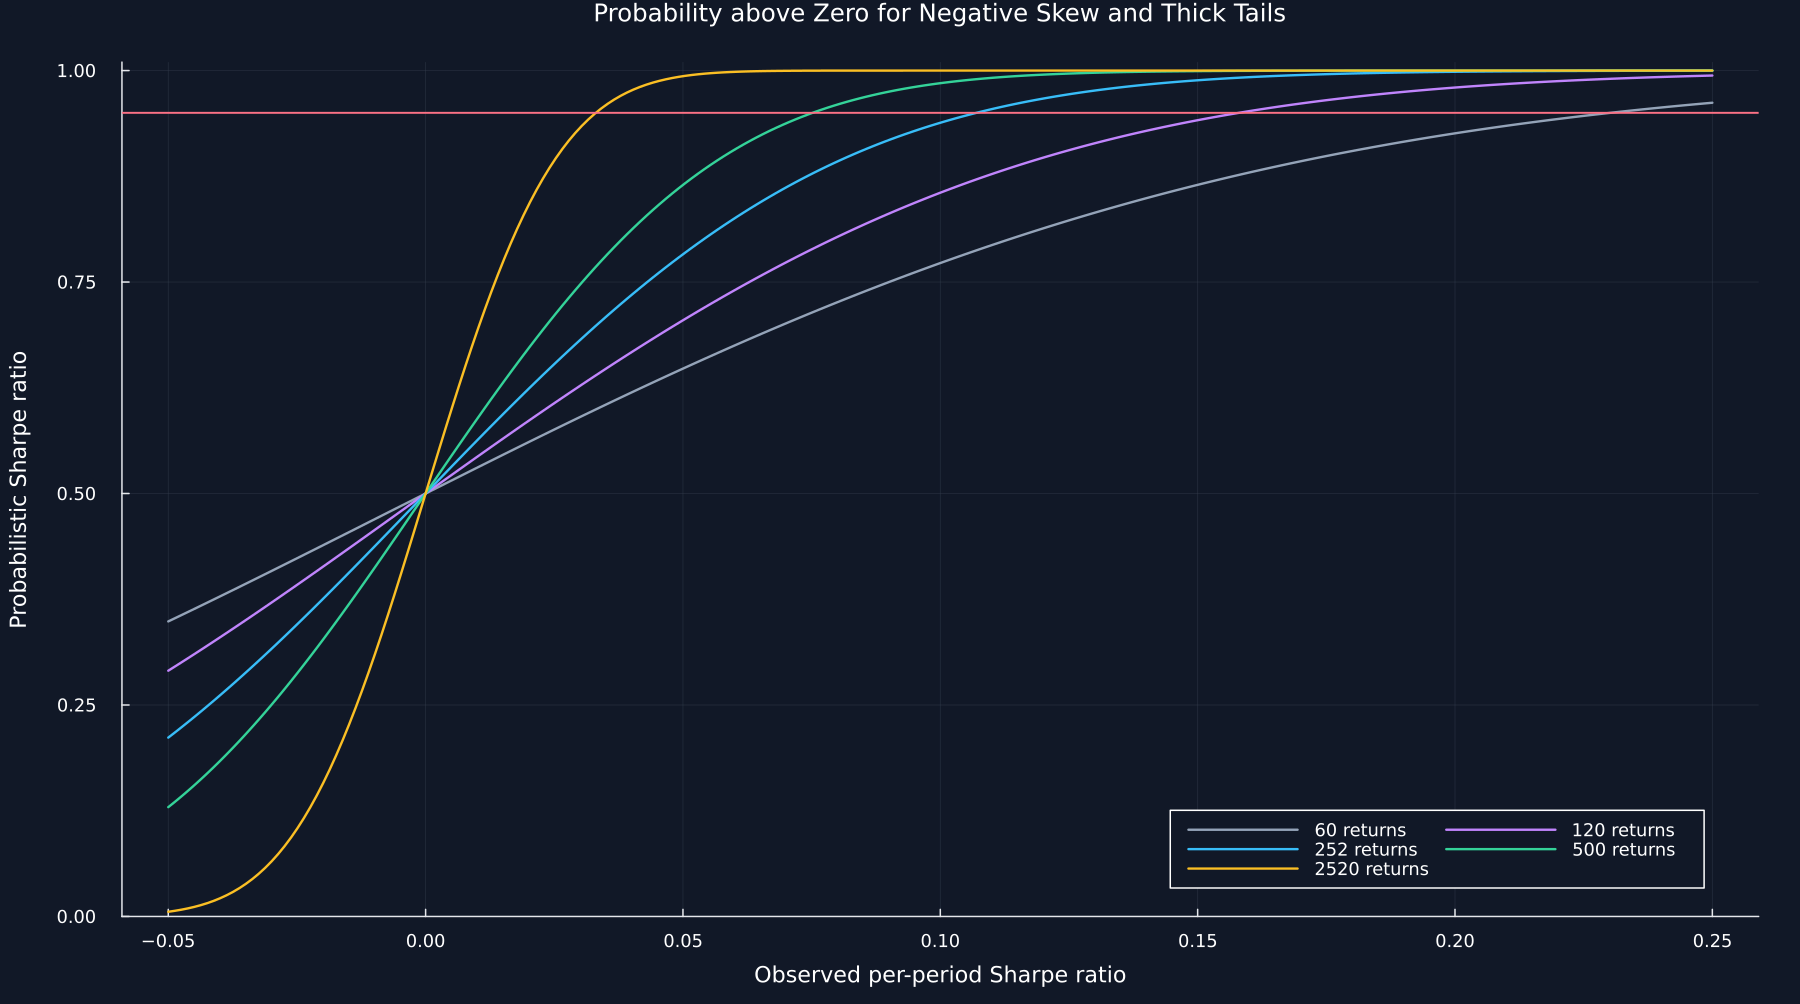

In [4]:
sample_sizes,observed_values = [60,120,252,500,2520],[.02,.05,.10,.15,.20]
psr_sensitivity = DataFrame([(returns=count,sharpe=value,normal=psr(value,0.,count),nonnormal=psr(value,0.,count,-.5,4.)) for count in sample_sizes for value in observed_values])
rename!(psr_sensitivity,["Returns","Observed Sharpe","Normal returns","Negative skew and thick tails"])
preliminary_psr_reproduction = DataFrame("Calculation"=>["Preliminary numerical input","Daily value consistent with annual Sharpe"],"Sharpe used in formula"=>[1.98,1.98/sqrt(252.)],"Returns"=>[2520,2520],"Skewness"=>[-.5,-.5],"Kurtosis"=>[4.,4.],"PSR against zero"=>[psr(value,0.,2520,-.5,4.) for value in [1.98,1.98/sqrt(252.)]])
table(psr_sensitivity,"psr_sensitivity","Probabilistic Sharpe ratios across sample lengths and return shapes.")
table(preliminary_psr_reproduction,"preliminary_psr_reproduction","The preliminary PSR calculation and a frequency-consistent daily conversion.")
sharpe_grid = collect(range(-.05,.25;length=240))
curves = DataFrame(sharpe=sharpe_grid)
figure = plot(;xlabel="Observed per-period Sharpe ratio",ylabel="Probabilistic Sharpe ratio",title="Probability above Zero for Negative Skew and Thick Tails",ylims=(0,1.01),legend=:bottomright,legendcolumns=2,size=(1200,670))
for (count,color) in zip(sample_sizes,["#94A3B8",violet,palette.cyan,palette.green,palette.amber])
    values = [psr(sharpe,0.,count,-.5,4.) for sharpe in sharpe_grid]
    curves[!,"returns_"*string(count)] = values
    plot!(figure,sharpe_grid,values;color,label=string(count)*" returns",linewidth=1.6)
end
hline!(figure,[.95];color=palette.rose,label="",linewidth=1.3)
save_data(curves,paths,"psr_curves")
save_figure(figure,paths,"psr_curves")


## Tests

In [5]:
@assert issorted(price_dates)
@assert allunique(price_dates)
@assert length(prices)==2330
@assert observation_count==2090
@assert trial_count==32
@assert size(strategy_catalog)==(32,5)
@assert size(public_sharpe_inference)==(32,8)
@assert size(leading_public_inference)==(10,8)
@assert all(value->0<=value<=1,public_sharpe_inference[!,"PSR against zero"])
@assert all(value->0<=value<=1,public_sharpe_inference[!,"Deflated probability"])
@assert benchmark_sharpe_ratio(trial_sharpes)≈expected_max_sharpe_ratio(trial_count,0.,trial_spread)
@assert expected_maximum_sensitivity.Trials==trial_counts
@assert issorted(expected_maximum_sensitivity[!,"Benchmark when mean is zero"])
@assert size(expected_maximum_simulation)==(4,5)
@assert all(abs.(expected_maximum_simulation[!,"Simulated mean maximum"].-expected_maximum_simulation[!,"Analytical expected maximum"]).<=3 .*expected_maximum_simulation[!,"Simulated standard error"].+.015)
@assert length(preliminary_maxima)==1000
@assert 1.20<mean(preliminary_maxima)<1.35
@assert size(psr_sensitivity)==(25,4)
@assert size(preliminary_psr_reproduction)==(2,6)
@assert all(value->0<=value<=1,preliminary_psr_reproduction[!,"PSR against zero"])
@assert estimated_sharpe_ratio_z_statistics(.1,120;true_sharpe_ratio=0.,skew=-.5,kurt=4.)≈psr(.1,0.,120,-.5,4.;return_test_statistic=true)
@assert isfile(joinpath(paths.figures,"public_deflated_sharpe.pdf"))
@assert isfile(joinpath(paths.figures,"expected_maximum_curve.pdf"))
@assert isfile(joinpath(paths.figures,"psr_curves.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"public_sharpe_inference.tex"))
@assert isfile(joinpath(paths.tables,"leading_public_inference.tex"))
@assert isfile(joinpath(paths.tables,"expected_maximum_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"expected_maximum_simulation.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_expected_max_reproduction.tex"))
@assert isfile(joinpath(paths.tables,"psr_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_psr_reproduction.tex"))
